# Credit scoring Ngân hàng Sông Hồng - Logistic Regression từ đầu đến cuối

Bài toán: dự đoán một khoản vay có trở thành **Bad** (từng quá hạn 90+ ngày trong 12 tháng đầu) hay không, chỉ từ thông tin biết được **lúc nộp hồ sơ**.

Notebook làm đủ 5 bước, mỗi bước xong mới sang bước sau:

1. Nạp dữ liệu và quan sát ban đầu
2. Định nghĩa nhãn, chọn dòng, EDA thời gian, chia train / val / test (70 / 15 / 15)
3. Làm sạch dữ liệu và dựng pipeline (học trên train, áp dụng cho val / test)
4. Feature engineering
5. Mô hình Logistic Regression

**Quy tắc:** mỗi hàm một ô code, mỗi kết quả một ô code. Markdown chỉ giải thích *làm gì* và *vì sao*. Mọi con số và nhận xét do ô code ngay bên dưới in ra.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

In [2]:
SEED = 42
DATA = Path("../data/song_hong")
FIG_DIR = Path("../artifacts/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)

In [3]:
FILES = ["data_dictionary.csv", "song_hong_dev_2023.csv", "song_hong_oot_2024H1.csv", "song_hong_perf_monthly.csv"]
missing_files = [f for f in FILES if not (DATA / f).exists()]
if missing_files:
    raise FileNotFoundError(f"Thiếu file trong {DATA}: {missing_files}")
print("Đủ file:", FILES)

Đủ file: ['data_dictionary.csv', 'song_hong_dev_2023.csv', 'song_hong_oot_2024H1.csv', 'song_hong_perf_monthly.csv']


---
# Bước 1 - Nạp dữ liệu và quan sát ban đầu

## 1.1 Nạp các file

| File | Nội dung |
|---|---|
| `data_dictionary.csv` | Từ điển cột: ý nghĩa, vai trò (đặc trưng / phân khúc / hệ thống) |
| `song_hong_dev_2023.csv` | Hồ sơ nộp năm 2023, có cả hồ sơ bị từ chối |
| `song_hong_oot_2024H1.csv` | Hồ sơ nộp nửa đầu 2024 (giai đoạn sau, tên "out-of-time") |
| `song_hong_perf_monthly.csv` | Số ngày quá hạn từng tháng của các khoản vay đã được duyệt |

In [4]:
dictionary = pd.read_csv(DATA / "data_dictionary.csv", encoding="utf-8-sig")
dev = pd.read_csv(DATA / "song_hong_dev_2023.csv", parse_dates=["app_date"])
oot = pd.read_csv(DATA / "song_hong_oot_2024H1.csv", parse_dates=["app_date"])
perf = pd.read_csv(DATA / "song_hong_perf_monthly.csv")

In [5]:
print(f"dev 2023: {dev.shape} | oot 2024H1: {oot.shape} | perf hàng tháng: {perf.shape} | từ điển: {dictionary.shape}")

dev 2023: (66000, 27) | oot 2024H1: (12000, 25) | perf hàng tháng: (59000, 28) | từ điển: (27, 9)


## 1.2 Từ điển cột

Cột `vai_tro` cho biết cột nào là **đặc trưng** (dùng làm input), cột nào chỉ để phân khúc hoặc là cột hệ thống (kết quả, quyết định cũ). Cột hệ thống như `decision`, `perf_class`, `target` có sau khi hồ sơ đã được xử lý nên **không được dùng làm input**.

In [6]:
dictionary[["column", "mo_ta", "kieu", "vai_tro", "nhom_thong_tin"]]

,column,mo_ta,kieu,vai_tro,nhom_thong_tin
0,app_id,Mã hồ sơ,text,Hệ thống,NaN
1,app_date,Ngày nộp hồ sơ,date,Hệ thống,NaN
2,channel,Kênh nộp hồ sơ,category,Phân khúc,NaN
3,customer_type,Loại khách hàng,category,Phân khúc,NaN
4,province,Tỉnh/thành,category,Phân khúc,NaN
5,region,Vùng,category,Phân khúc,NaN
6,loan_amount_mil,Số tiền vay (triệu VND),number,Đặc trưng,Khả năng trả nợ
7,age,Tuổi,number,Đặc trưng,Nhân khẩu & ổn định
8,gender,Giới tính,category,Đặc trưng,Nhân khẩu & ổn định
9,occupation,Nghề nghiệp,category,Đặc trưng,Nhân khẩu & ổn định


In [7]:
assert set(dev.columns) == set(dictionary["column"]), "Cột của file dev không khớp từ điển"
print("Từ điển khớp đúng các cột của file dev.")
print(dictionary["vai_tro"].value_counts().to_string())

Từ điển khớp đúng các cột của file dev.
vai_tro
Đặc trưng    15
Hệ thống      8
Phân khúc     4


## 1.3 Kiểu dữ liệu, giá trị thiếu, số giá trị khác nhau

In [8]:
def describe_columns(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "thieu_%": df.isna().mean() * 100,
        "so_gia_tri_khac_nhau": df.nunique(),
    })

In [9]:
describe_columns(dev)

,dtype,thieu_%,so_gia_tri_khac_nhau
app_id,str,0.000,66000
app_date,datetime64[us],0.000,336
channel,str,0.000,3
customer_type,str,0.000,2
province,str,0.000,8
region,str,0.000,3
loan_amount_mil,int64,0.000,291
age,int64,0.000,64
gender,str,0.000,2
occupation,str,0.000,5


## 1.4 Cấu trúc kết quả: hồ sơ nào có kết quả vay?

Cột `decision` là quyết định của scorecard cũ, cột `perf_class` là phân loại kết quả. Ta xem hai cột này đi cùng nhau thế nào.

In [10]:
pd.crosstab(dev["decision"], dev["perf_class"], margins=True)

perf_class,Bad,Excluded,Good,Indeterminate,Rejected,All
decision,,,,,,
Approved,2000,800,38000,6200,0,47000
Rejected,0,0,0,0,19000,19000
All,2000,800,38000,6200,19000,66000


In [11]:
print("File OOT:", oot["perf_class"].value_counts().to_dict())
print(f"dev: {dev.app_date.min():%Y-%m-%d} đến {dev.app_date.max():%Y-%m-%d} | oot: {oot.app_date.min():%Y-%m-%d} đến {oot.app_date.max():%Y-%m-%d}")

File OOT: {'Good': 11381, 'Bad': 619}
dev: 2023-01-01 đến 2023-12-28 | oot: 2024-01-01 đến 2024-06-28


In [12]:
approved_ids = pd.concat([dev, oot]).query("decision == 'Approved'")["app_id"]
assert dev["app_id"].is_unique and oot["app_id"].is_unique and perf["app_id"].is_unique
assert perf["app_id"].isin(approved_ids).all() and approved_ids.isin(perf["app_id"]).all()
print("app_id không trùng; file perf có đúng một dòng cho mỗi hồ sơ đã được duyệt.")

app_id không trùng; file perf có đúng một dòng cho mỗi hồ sơ đã được duyệt.


---
# Bước 2 - Nhãn, chọn dòng, EDA thời gian, chia tập

## 2.1 Kiểm chứng nhãn bằng dữ liệu quá hạn từng tháng

Quy tắc phân loại (theo số ngày quá hạn lớn nhất trong 12 tháng đầu):

| Nhãn | Quy tắc | Dùng để xây mô hình? |
|---|---|---|
| Good | Không quá hạn ngày nào | Có |
| Bad | Quá hạn từ 90 ngày trở lên | Có |
| Indeterminate | Quá hạn 1-89 ngày, hoặc hủy vay tự nguyện | Loại |
| Excluded | Nhân viên ngân hàng, gian lận đã xác nhận | Loại |
| Rejected | Hồ sơ bị từ chối, không có khoản vay nên không có kết quả | Loại |

Thay vì tin cột `perf_class` có sẵn, ta tự tính số ngày quá hạn lớn nhất từ file `perf` rồi đối chiếu.

In [13]:
def max_dpd_first_12m(perf):
    dpd_cols = [f"dpd_{m:02d}" for m in range(1, 13)]
    return perf.set_index("app_id")[dpd_cols].max(axis=1).rename("max_dpd_check")

In [14]:
all_apps = pd.concat([dev, oot], ignore_index=True)
all_apps = all_apps.merge(max_dpd_first_12m(perf), on="app_id", how="left")
all_apps["dpd_band"] = pd.cut(all_apps["max_dpd_check"], [-1, 0, 89, 10_000], labels=["0 ngày", "1-89 ngày", "90+ ngày"])

In [15]:
pd.crosstab(all_apps["perf_class"], all_apps["dpd_band"], margins=True)

dpd_band,0 ngày,1-89 ngày,90+ ngày,All
perf_class,,,,
Bad,0,0,2619,2619
Excluded,620,0,180,800
Good,49381,0,0,49381
Indeterminate,840,5360,0,6200
All,50841,5360,2799,59000


In [16]:
good_max = all_apps.loc[all_apps.perf_class == "Good", "max_dpd_check"].max()
bad_min = all_apps.loc[all_apps.perf_class == "Bad", "max_dpd_check"].min()
indet = all_apps[all_apps.perf_class == "Indeterminate"].groupby("indeterminate_reason")["max_dpd_check"].agg(["count", "min", "max"])
print(f"Good: số ngày quá hạn lớn nhất = {good_max:.0f}. Bad: số ngày quá hạn nhỏ nhất = {bad_min:.0f}.")
print("Indeterminate theo lý do:")
print(indet)

Good: số ngày quá hạn lớn nhất = 0. Bad: số ngày quá hạn nhỏ nhất = 90.
Indeterminate theo lý do:
                      count   min    max
indeterminate_reason                    
DPD 1–89               5360 1.000 89.000
Hủy tự nguyện           840 0.000  0.000


In [17]:
excl = all_apps[all_apps.perf_class == "Excluded"].groupby("exclusion_reason")["max_dpd_check"].agg(["count", "min", "max"])
print("Excluded theo lý do:")
print(excl)
print(f"-> Nếu không loại Excluded, {(all_apps.loc[all_apps.perf_class == 'Excluded', 'max_dpd_check'] >= 90).sum()} hồ sơ trong số này sẽ bị tính nhầm là Bad do có quá hạn 90+ ngày.")

Excluded theo lý do:
                      count     min     max
exclusion_reason                           
Gian lận đã xác nhận    180 360.000 360.000
Nhân viên ngân hàng     620   0.000   0.000
-> Nếu không loại Excluded, 180 hồ sơ trong số này sẽ bị tính nhầm là Bad do có quá hạn 90+ ngày.


## 2.2 Chọn dòng: bảng phễu

Chỉ giữ Good và Bad. Mỗi bước loại in số dòng còn lại để có bảng đưa vào báo cáo.

In [18]:
def funnel_table(df):
    steps = [("Tất cả hồ sơ", df)]
    for label_name, drop_class in [("Bỏ Rejected (không có khoản vay)", "Rejected"),
                                   ("Bỏ Excluded", "Excluded"),
                                   ("Bỏ Indeterminate", "Indeterminate")]:
        df = df[df["perf_class"] != drop_class]
        steps.append((label_name, df))
    return pd.DataFrame({"Bước": [s[0] for s in steps], "Số dòng còn lại": [len(s[1]) for s in steps]}).set_index("Bước")

In [19]:
funnel_table(all_apps)

,Số dòng còn lại
Bước,
Tất cả hồ sơ,78000
Bỏ Rejected (không có khoản vay),59000
Bỏ Excluded,58200
Bỏ Indeterminate,52000


In [20]:
model_df = all_apps[all_apps["perf_class"].isin(["Good", "Bad"])].copy()
assert model_df["target"].isin([0, 1]).all()
assert (model_df["target"] == (model_df["perf_class"] == "Bad")).all()
print(f"Dùng {len(model_df):,} hồ sơ. Tỷ lệ Bad: {model_df['target'].mean():.2%}")

Dùng 52,000 hồ sơ. Tỷ lệ Bad: 5.04%


## 2.3 Giới hạn của việc chỉ học trên hồ sơ được duyệt

Mô hình chỉ thấy khách hàng **đã được duyệt**, vì hồ sơ bị từ chối không có kết quả. Ô dưới so sánh hồ sơ được duyệt và bị từ chối trong file dev để xem hai nhóm khác nhau thế nào.

In [21]:
by_decision = dev.groupby("decision")[["dti_pct", "dpd_cnt_12m", "inq_6m", "num_lenders"]].mean()
by_decision

,dti_pct,dpd_cnt_12m,inq_6m,num_lenders
decision,,,,
Approved,46.077,0.329,1.640,1.521
Rejected,56.678,0.943,2.644,2.116


In [22]:
print(f"dpd_cnt_12m trung bình: bị từ chối {by_decision.loc['Rejected', 'dpd_cnt_12m']:.2f} so với được duyệt {by_decision.loc['Approved', 'dpd_cnt_12m']:.2f}.")
print(f"dti_pct trung bình: bị từ chối {by_decision.loc['Rejected', 'dti_pct']:.1f} so với được duyệt {by_decision.loc['Approved', 'dti_pct']:.1f}.")
print("-> Hồ sơ bị từ chối rủi ro hơn. Mô hình học trên nhóm đã được duyệt sẽ ít thấy khách rủi ro cao. Đây là hạn chế cần ghi trong báo cáo.")

dpd_cnt_12m trung bình: bị từ chối 0.94 so với được duyệt 0.33.
dti_pct trung bình: bị từ chối 56.7 so với được duyệt 46.1.
-> Hồ sơ bị từ chối rủi ro hơn. Mô hình học trên nhóm đã được duyệt sẽ ít thấy khách rủi ro cao. Đây là hạn chế cần ghi trong báo cáo.


## 2.4 EDA thời gian

Ta chỉ hỏi về **cấu trúc thời gian**: số hồ sơ mỗi tháng, tỷ lệ Bad từng tháng, và thu nhập khai báo có đổi theo thời gian không. Không xem quan hệ feature-nhãn trước khi chia tập.

In [23]:
model_df["month"] = model_df["app_date"].dt.to_period("M")
monthly = model_df.groupby("month").agg(so_ho_so=("target", "size"),
                                        ty_le_bad=("target", "mean"),
                                        thu_nhap_trung_vi=("income_mil", "median"))
monthly

,so_ho_so,ty_le_bad,thu_nhap_trung_vi
month,,,
2023-01,3305,0.044,12.000
2023-02,3137,0.049,13.000
2023-03,3172,0.051,12.000
2023-04,3190,0.042,12.000
2023-05,3208,0.053,12.000
2023-06,3236,0.043,12.000
2023-07,3513,0.052,16.000
2023-08,3395,0.054,15.000
2023-09,3435,0.056,15.000


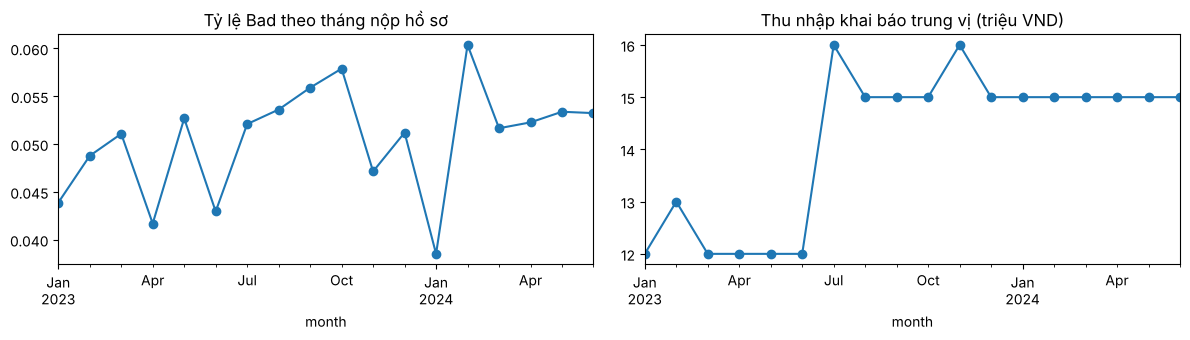

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
monthly["ty_le_bad"].plot(ax=axes[0], marker="o", title="Tỷ lệ Bad theo tháng nộp hồ sơ")
monthly["thu_nhap_trung_vi"].plot(ax=axes[1], marker="o", title="Thu nhập khai báo trung vị (triệu VND)")
plt.tight_layout()
plt.savefig(FIG_DIR / "song_hong_eda_thoi_gian.png", dpi=150, bbox_inches="tight")
plt.show()

In [25]:
before = model_df.loc[model_df.app_date < "2023-07-01", "income_mil"].median()
after = model_df.loc[model_df.app_date >= "2023-07-01", "income_mil"].median()
print(f"Thu nhập trung vị trước 01/07/2023: {before:.1f} triệu | từ 01/07/2023: {after:.1f} triệu")
print(f"Tỷ lệ Bad thấp nhất / cao nhất theo tháng: {monthly.ty_le_bad.min():.2%} / {monthly.ty_le_bad.max():.2%}")

Thu nhập trung vị trước 01/07/2023: 12.0 triệu | từ 01/07/2023: 15.0 triệu
Tỷ lệ Bad thấp nhất / cao nhất theo tháng: 3.85% / 6.04%


Từ điển ghi rằng biểu mẫu mới từ 01/07/2023 làm thu nhập khai báo tăng. Ô trên kiểm chứng điều đó trên dữ liệu. Ta **giữ cả hai giai đoạn** và ghi đây là rủi ro: mô hình học từ dữ liệu có hai cách khai báo thu nhập.

## 2.5 Chia 70 / 15 / 15 theo thời gian

Sắp theo ngày nộp, cắt hai **ngày** tại vị trí 70% và 85%. Cắt theo ngày (không cắt giữa một ngày) để không có hồ sơ cùng ngày nằm ở hai tập.

In [26]:
def split_by_time(df, date_col="app_date", train_share=0.70, val_share=0.85):
    df = df.sort_values([date_col, "app_id"]).reset_index(drop=True)
    cut1 = df.loc[int(len(df) * train_share), date_col]
    cut2 = df.loc[int(len(df) * val_share), date_col]
    train = df[df[date_col] < cut1]
    val = df[(df[date_col] >= cut1) & (df[date_col] < cut2)]
    test = df[df[date_col] >= cut2]
    return train, val, test, cut1, cut2

In [27]:
train, val, test, cut1, cut2 = split_by_time(model_df)
assert train["app_date"].max() < val["app_date"].min()
assert val["app_date"].max() < test["app_date"].min()
assert len(train) + len(val) + len(test) == len(model_df)
print("Thứ tự thời gian train < val < test được giữ.")

Thứ tự thời gian train < val < test được giữ.


In [28]:
pd.DataFrame({
    "số dòng": [len(train), len(val), len(test)],
    "tỷ lệ so với tổng": [len(x) / len(model_df) for x in (train, val, test)],
    "ngày đầu": [x["app_date"].min().date() for x in (train, val, test)],
    "ngày cuối": [x["app_date"].max().date() for x in (train, val, test)],
    "tỷ lệ Bad": [x["target"].mean() for x in (train, val, test)],
}, index=["train", "val", "test"])

,số dòng,tỷ lệ so với tổng,ngày đầu,ngày cuối,tỷ lệ Bad
train,36396,0.700,2023-01-01,2023-11-27,0.050
val,7785,0.150,2023-11-28,2024-03-02,0.051
test,7819,0.150,2024-03-03,2024-06-28,0.052


---
# Bước 3 - Làm sạch dữ liệu và pipeline

Hai loại việc, tách riêng:

- **Quy tắc cố định theo từng dòng** (lỗi nhập liệu theo từ điển): không học gì từ dữ liệu nên viết thành một hàm.
- **Việc học một con số từ dữ liệu** (trung vị để điền thiếu, trung bình và độ lệch chuẩn để chuẩn hóa, danh sách giá trị one-hot): đặt trong `Pipeline`, chỉ `fit` trên train.

## 3.1 Chọn cột đầu vào từ từ điển

Lấy cột có `vai_tro = Đặc trưng`. Bỏ `gender` vì từ điển ghi đây là biến nhạy cảm, không đưa vào mô hình.

In [29]:
is_feature = (dictionary["vai_tro"] == "Đặc trưng") & (dictionary["column"] != "gender")
feature_dict = dictionary[is_feature]
NUM_COLS = feature_dict.loc[feature_dict["kieu"] == "number", "column"].tolist()
CAT_COLS = feature_dict.loc[feature_dict["kieu"] == "category", "column"].tolist()
print("Cột số:", NUM_COLS)
print("Cột phân loại:", CAT_COLS)

Cột số: ['loan_amount_mil', 'age', 'income_mil', 'work_months', 'dti_pct', 'cic_hist_months', 'num_lenders', 'card_util_pct', 'inq_6m', 'dpd_cnt_6m', 'dpd_cnt_12m', 'deposit_avg_3m_mil']
Cột phân loại: ['occupation', 'home_status']


## 3.2 Các lỗi nhập liệu ghi trong từ điển

Từ điển nêu các giá trị bất thường: tuổi ngoài 18-75, thu nhập lớn hơn 500 triệu (lỗi đơn vị), `dti_pct` trên 200, thời gian làm việc và lịch sử tín dụng dài hơn số tháng kể từ năm 18 tuổi. Đếm chúng trên **train**.

In [30]:
def count_anomalies(df):
    months_since_18 = (df["age"] - 18) * 12
    return pd.Series({
        "tuổi ngoài 18-75": ((df["age"] < 18) | (df["age"] > 75)).sum(),
        "thu nhập > 500 triệu": (df["income_mil"] > 500).sum(),
        "dti_pct > 200": (df["dti_pct"] > 200).sum(),
        "work_months > số tháng từ 18 tuổi": (df["work_months"] > months_since_18).sum(),
        "cic_hist_months > số tháng từ 18 tuổi": (df["cic_hist_months"] > months_since_18).sum(),
    })

In [31]:
count_anomalies(train).to_frame("số dòng trên train")

,số dòng trên train
tuổi ngoài 18-75,110
thu nhập > 500 triệu,69
dti_pct > 200,12
work_months > số tháng từ 18 tuổi,49
cic_hist_months > số tháng từ 18 tuổi,55


Cách xử lý (công thức cố định): giá trị sai về nghiệp vụ (tuổi, thu nhập, thời gian) đổi thành trống để pipeline điền sau. `dti_pct` cực lớn thì cắt ở 200 vì vẫn là giá trị thật nhưng quá lớn. `card_util_pct` trên 100% **giữ nguyên** vì từ điển ghi đó là chi tiêu vượt hạn mức, không phải lỗi.

In [32]:
def clean(df):
    df = df.astype({c: float for c in NUM_COLS})
    df.loc[(df["age"] < 18) | (df["age"] > 75), "age"] = np.nan
    df.loc[df["income_mil"] > 500, "income_mil"] = np.nan
    df["dti_pct"] = df["dti_pct"].clip(upper=200)
    max_months = (df["age"] - 18) * 12
    for col in ["work_months", "cic_hist_months"]:
        df.loc[df[col] > max_months, col] = np.nan
    return df

In [33]:
train_c, val_c, test_c = clean(train), clean(val), clean(test)
after = pd.DataFrame({"train": count_anomalies(train_c), "val": count_anomalies(val_c), "test": count_anomalies(test_c)})
assert (after == 0).all().all()
print("Sau khi làm sạch, mọi loại lỗi đều bằng 0 ở cả ba tập.")

Sau khi làm sạch, mọi loại lỗi đều bằng 0 ở cả ba tập.


## 3.3 Giá trị thiếu

Xem tỷ lệ thiếu trên train sau khi làm sạch.

In [34]:
missing_train = train_c[NUM_COLS + CAT_COLS].isna().mean().mul(100)
missing_train[missing_train > 0].sort_values(ascending=False).to_frame("thiếu % (train)")

,thiếu % (train)
deposit_avg_3m_mil,38.128
card_util_pct,30.611
work_months,10.314
income_mil,4.665
age,0.302


Từ điển ghi `card_util_pct` trống nghĩa là **không có thẻ** (chỉ có thẻ khi có ít nhất một tổ chức tín dụng). Kiểm tra điều đó trên train.

In [35]:
no_lender = train_c["num_lenders"] == 0
share_no_card_when_no_lender = train_c.loc[no_lender, "card_util_pct"].isna().mean()
share_no_card_when_lender = train_c.loc[~no_lender, "card_util_pct"].isna().mean()
print(f"Khách chưa có dư nợ TCTD (num_lenders = 0): {share_no_card_when_no_lender:.1%} không có thông tin thẻ.")
print(f"Khách đã có dư nợ TCTD: {share_no_card_when_lender:.1%} không có thông tin thẻ.")

Khách chưa có dư nợ TCTD (num_lenders = 0): 100.0% không có thông tin thẻ.
Khách đã có dư nợ TCTD: 4.6% không có thông tin thẻ.


Vì trống có thể mang ý nghĩa ("không có thẻ", "không có tiền gửi", "không khai thu nhập"), pipeline dùng `SimpleImputer(..., add_indicator=True)`: điền trung vị **và** thêm một cột 0/1 cho biết dòng đó từng bị trống. Cột phân loại không có giá trị thiếu (kiểm tra ở ô trên), nên không cần điền.

## 3.4 Pipeline

In [36]:
def make_preprocessor(num_cols, cat_cols):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    categorical = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)])

## 3.5 Chứng minh pipeline chỉ học từ train

Fit trên train, rồi so con số pipeline đã học với con số tính trực tiếp trên val. Hai con số khác nhau nghĩa là val không được dùng để học.

In [37]:
prep = make_preprocessor(NUM_COLS, CAT_COLS).fit(train_c[NUM_COLS + CAT_COLS])
i = NUM_COLS.index("income_mil")
learned_median = prep.named_transformers_["num"]["impute"].statistics_[i]
print(f"Trung vị income_mil pipeline đã học (từ train): {learned_median}")
print(f"Trung vị income_mil tính trên val:              {val_c['income_mil'].median()}")

Trung vị income_mil pipeline đã học (từ train): 14.0
Trung vị income_mil tính trên val:              15.0


In [38]:
age_idx = NUM_COLS.index("age")
age_train = prep.transform(train_c[NUM_COLS + CAT_COLS])[:, age_idx]
age_val = prep.transform(val_c[NUM_COLS + CAT_COLS])[:, age_idx]
print(f"Sau chuẩn hóa, trung bình cột age: train = {age_train.mean():.4f}, val = {age_val.mean():.4f}")
print(f"Kích thước đầu ra: train {prep.transform(train_c[NUM_COLS + CAT_COLS]).shape}")

Sau chuẩn hóa, trung bình cột age: train = 0.0000, val = -0.0253


Kích thước đầu ra: train (36396, 25)


---
# Bước 4 - Feature engineering

Ba feature mới, mỗi cái là công thức cố định theo từng dòng, có lý do nghiệp vụ:

| Feature | Công thức | Vì sao |
|---|---|---|
| `loan_to_income` | số tiền vay / (thu nhập tháng x 12) | Khoản vay lớn so với thu nhập khó trả hơn, `loan_amount_mil` đứng riêng không nói lên điều đó |
| `dpd_older` | `dpd_cnt_12m` - `dpd_cnt_6m` | Từ điển ghi hai cột này tương quan cao và 6m luôn nhỏ hơn hoặc bằng 12m; hiệu số là số lần trễ hạn của 6 tháng trước đó |
| `deposit_to_loan` | tiền gửi bình quân / số tiền vay (trống = 0) | Khả năng tự trả bằng tiền gửi |

In [39]:
def add_features(df):
    df = df.copy()
    df["loan_to_income"] = df["loan_amount_mil"] / (df["income_mil"] * 12)
    df["dpd_older"] = df["dpd_cnt_12m"] - df["dpd_cnt_6m"]
    df["deposit_to_loan"] = df["deposit_avg_3m_mil"].fillna(0) / df["loan_amount_mil"]
    return df

In [40]:
train_f, val_f, test_f = add_features(train_c), add_features(val_c), add_features(test_c)
NEW_COLS = ["loan_to_income", "dpd_older", "deposit_to_loan"]
for name, d in [("train", train_f), ("val", val_f), ("test", test_f)]:
    assert not np.isinf(d[NEW_COLS]).any().any(), f"Có giá trị vô cùng ở {name}"
print("Không có giá trị vô cùng (chia cho 0) ở feature mới.")

Không có giá trị vô cùng (chia cho 0) ở feature mới.


## 4.1 Kiểm tra feature mới trên train

Mỗi feature đứng một mình được chấm bằng ROC-AUC trên **train** (điền trống bằng trung vị; nếu AUC dưới 0,5 thì đảo chiều, vì cột chỉ ngược chiều với nhãn). AUC bằng 0,5 là không phân biệt được gì. So feature mới với các cột dùng để tạo ra nó.

In [41]:
def single_auc(x, y):
    x = x.fillna(x.median())
    auc = roc_auc_score(y, x)
    return max(auc, 1 - auc)

In [42]:
pairs = {
    "loan_to_income": ["loan_amount_mil", "income_mil"],
    "dpd_older": ["dpd_cnt_12m", "dpd_cnt_6m"],
    "deposit_to_loan": ["deposit_avg_3m_mil", "loan_amount_mil"],
}
rows = []
for new, parts in pairs.items():
    rows.append({"feature": new, "loại": "mới", "AUC trên train": single_auc(train_f[new], train_f["target"])})
    for p in parts:
        rows.append({"feature": p, "loại": f"gốc (của {new})", "AUC trên train": single_auc(train_f[p], train_f["target"])})
pd.DataFrame(rows).set_index("feature")

,loại,AUC trên train
feature,,
loan_to_income,mới,0.576
loan_amount_mil,gốc (của loan_to_income),0.509
income_mil,gốc (của loan_to_income),0.606
dpd_older,mới,0.570
dpd_cnt_12m,gốc (của dpd_older),0.662
dpd_cnt_6m,gốc (của dpd_older),0.639
deposit_to_loan,mới,0.555
deposit_avg_3m_mil,gốc (của deposit_to_loan),0.573
loan_amount_mil,gốc (của deposit_to_loan),0.509


In [43]:
train_f[["dpd_cnt_6m", "dpd_cnt_12m", "dpd_older"]].corr()

,dpd_cnt_6m,dpd_cnt_12m,dpd_older
dpd_cnt_6m,1.000,0.889,0.153
dpd_cnt_12m,0.889,1.000,0.589
dpd_older,0.153,0.589,1.000


Feature mới có thật sự giúp mô hình hay không sẽ được quyết định ở bước 5 bằng cách so sánh hai bộ feature trên **validation**, không quyết định bằng AUC đứng riêng ở trên.

---
# Bước 5 - Mô hình Logistic Regression

Hai bộ feature: **A** (feature gốc) và **B** (gốc + 3 feature mới). Chọn bộ feature và hệ số điều chuẩn `C` (C càng nhỏ, mô hình càng bị kéo về đơn giản) bằng **AUC trên validation**. Test chỉ chạm **một lần** ở cuối.

## 5.1 Mức tham chiếu

Một mô hình không học gì (luôn đoán Good) có accuracy cao nhưng vô dụng với bài toán này, vì Bad là thiểu số. Vì vậy dùng ROC-AUC (đo khả năng xếp khách Bad cao hơn khách Good, 0,5 là ngẫu nhiên) và KS (khoảng cách lớn nhất giữa tỷ lệ Bad bắt được và tỷ lệ Good bị bắt nhầm).

In [44]:
print(f"Luôn đoán Good: accuracy trên val = {1 - val['target'].mean():.2%}, nhưng AUC = 0.5 và bắt được 0% khách Bad.")

Luôn đoán Good: accuracy trên val = 94.91%, nhưng AUC = 0.5 và bắt được 0% khách Bad.


In [45]:
def auc_ks(y, proba):
    fpr, tpr, _ = roc_curve(y, proba)
    return roc_auc_score(y, proba), (tpr - fpr).max()

In [46]:
def build_model(num_cols, C):
    return Pipeline([
        ("prep", make_preprocessor(num_cols, CAT_COLS)),
        ("lr", LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
    ])

## 5.2 Chọn bộ feature và C trên validation

In [47]:
FEATURE_SETS = {"A: gốc": NUM_COLS, "B: gốc + mới": NUM_COLS + NEW_COLS}
y_train, y_val, y_test = train_f["target"], val_f["target"], test_f["target"]

rows = []
for set_name, num_cols in FEATURE_SETS.items():
    cols = num_cols + CAT_COLS
    for C in [0.001, 0.01, 0.1, 1]:
        model = build_model(num_cols, C).fit(train_f[cols], y_train)
        rows.append({"bộ feature": set_name, "C": C,
                     "AUC train": roc_auc_score(y_train, model.predict_proba(train_f[cols])[:, 1]),
                     "AUC val": roc_auc_score(y_val, model.predict_proba(val_f[cols])[:, 1])})
grid = pd.DataFrame(rows)
grid

,bộ feature,C,AUC train,AUC val
0,A: gốc,0.001,0.776,0.768
1,A: gốc,0.010,0.780,0.768
2,A: gốc,0.100,0.780,0.767
3,A: gốc,1.000,0.780,0.767
4,B: gốc + mới,0.001,0.776,0.767
5,B: gốc + mới,0.010,0.780,0.768
6,B: gốc + mới,0.100,0.780,0.767
7,B: gốc + mới,1.000,0.780,0.767


In [48]:
best = grid.loc[grid["AUC val"].idxmax()]
best_set, best_C = best["bộ feature"], best["C"]
best_A = grid[grid["bộ feature"].str.startswith("A")]["AUC val"].max()
best_B = grid[grid["bộ feature"].str.startswith("B")]["AUC val"].max()
print(f"AUC val tốt nhất của bộ A: {best_A:.4f} | của bộ B: {best_B:.4f} | chênh lệch (B - A): {best_B - best_A:+.4f}")
print(f"Chọn: bộ '{best_set}', C = {best_C}")
if best_B <= best_A:
    print("Feature mới không cải thiện AUC trên validation.")

AUC val tốt nhất của bộ A: 0.7682 | của bộ B: 0.7680 | chênh lệch (B - A): -0.0001
Chọn: bộ 'A: gốc', C = 0.01
Feature mới không cải thiện AUC trên validation.


## 5.3 Mô hình cuối cùng và các hệ số

Fit trên **train** với lựa chọn tốt nhất. Mọi cột số đã chuẩn hóa nên có thể so độ lớn hệ số giữa các cột số. Hệ số dương làm tăng xác suất Bad.

In [49]:
final_num = FEATURE_SETS[best_set]
final_cols = final_num + CAT_COLS
final_model = build_model(final_num, best_C).fit(train_f[final_cols], y_train)

In [50]:
names = final_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final_model.named_steps["lr"].coef_[0], index=names)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12).to_frame("hệ số")

,hệ số
num__cic_hist_months,-0.369
num__card_util_pct,0.311
num__dpd_cnt_12m,0.304
cat__occupation_Kinh doanh tự do,0.281
cat__occupation_Văn phòng,-0.259
num__dti_pct,0.188
num__work_months,-0.169
num__inq_6m,0.154
num__income_mil,-0.110
cat__occupation_Khác,-0.099


## 5.4 Đánh giá cuối: train, val, test

In [51]:
results = {}
for name, d, y in [("train", train_f, y_train), ("val", val_f, y_val), ("test", test_f, y_test)]:
    results[name] = auc_ks(y, final_model.predict_proba(d[final_cols])[:, 1])
pd.DataFrame(results, index=["ROC-AUC", "KS"]).T

,ROC-AUC,KS
train,0.780,0.413
val,0.768,0.409
test,0.782,0.447


## 5.5 Xếp hạng rủi ro trên test

Chia khách trên test thành 10 nhóm bằng nhau theo xác suất Bad dự đoán (nhóm 0 thấp nhất, nhóm 9 cao nhất). Nếu mô hình xếp hạng tốt thì tỷ lệ Bad thực tế tăng dần theo nhóm.

In [52]:
test_proba = final_model.predict_proba(test_f[final_cols])[:, 1]
decile = pd.qcut(test_proba, 10, labels=False, duplicates="drop")
decile_table = test_f.assign(nhom=decile).groupby("nhom")["target"].agg(so_ho_so="size", ty_le_bad_thuc_te="mean")
decile_table

,so_ho_so,ty_le_bad_thuc_te
nhom,,
0,782,0.005
1,782,0.014
2,782,0.013
3,782,0.018
4,782,0.028
5,781,0.024
6,782,0.047
7,782,0.081
8,782,0.093


## 5.6 Kết luận từ số đã tính

In [53]:
auc_tr, auc_va, auc_te = results["train"][0], results["val"][0], results["test"][0]
print(f"AUC: train {auc_tr:.4f} | val {auc_va:.4f} | test {auc_te:.4f}. KS test: {results['test'][1]:.4f}.")
print(f"Chênh lệch AUC train - test: {auc_tr - auc_te:+.4f}.")
print(f"Tỷ lệ Bad thực tế ở nhóm rủi ro cao nhất: {decile_table['ty_le_bad_thuc_te'].iloc[-1]:.2%}, ở nhóm thấp nhất: {decile_table['ty_le_bad_thuc_te'].iloc[0]:.2%} (trung bình toàn test: {y_test.mean():.2%}).")
print(f"Tỷ lệ Bad có tăng đơn điệu theo 10 nhóm: {decile_table['ty_le_bad_thuc_te'].is_monotonic_increasing}.")

AUC: train 0.7799 | val 0.7682 | test 0.7819. KS test: 0.4469.
Chênh lệch AUC train - test: -0.0020.
Tỷ lệ Bad thực tế ở nhóm rủi ro cao nhất: 19.82%, ở nhóm thấp nhất: 0.51% (trung bình toàn test: 5.22%).
Tỷ lệ Bad có tăng đơn điệu theo 10 nhóm: False.


## Hạn chế cần ghi vào báo cáo

- Mô hình chỉ học trên khách **đã được duyệt**; khách bị từ chối không có kết quả (mục 2.3).
- Indeterminate (quá hạn 1-89 ngày, hủy tự nguyện) bị loại, nên mô hình không phân biệt được nhóm "gần Bad".
- Biểu mẫu khai thu nhập đổi giữa chừng (mục 2.4), nên cùng một mức thu nhập khai báo có thể mang ý nghĩa khác nhau ở hai giai đoạn.
- Test được chạm một lần ở mục 5.4, sau khi toàn bộ lựa chọn đã chốt trên train và validation.